# E17 - relevance reading of the transport map

**Author**: Konrad Jelen (kj)<br>
**Date**: 2026-10-12<br>
**Pipeline stage**: experiment - registered batch `E17`, hypotheses `E17-H82` to `E17-H86`<br>
**Execution model**: opus (one executor agent for the batch)

**Purpose** - measure whether the nearest ground cost of a report statement to a short client brief ranks the report
statements of the brief's target sections above the other statements, and whether four candidate annotations
(`E17-H82` to `E17-H85`) rank them better. Measure also whether a cutoff taken from the pair's own scores (`E17-H86`)
marks match and no match better than the shipped fixed cutoff.

**Terms used below**

- **baseline** - `b_i = min_j c_ij`, the nearest ground cost of report statement `i` over the brief statements `j`, with `c_ij = cost_matrix(E_report, E_brief)`; a lower value means a more relevant statement
- **relevance score** - a value for which a higher number means a more relevant statement; a cost is negated to give one
- **AUC** - the probability that a random positive statement has a higher relevance score than a random negative statement, ties count one half
- **positive / negative / neutral** - for a brief, the statements of its target sections / all other scored statements / the statements of `Key findings` and `Overview`, which are left out of every metric
- **control** - one of the 7 gold-tier summaries of the ibm article; its positives are the statements of part 1 and its negatives the statements of part 2
- **lever** - the changed score of one hypothesis: `H82` pre-pass, `H83` column standardisation, `H84` received mass, `H85` background contrast, `H86` per-pair Otsu cutoff

Nothing under `src/`, `tests/`, `docs/` or the fixture is edited. Every bar is the registered one and is applied
as written; a number that is reported without a bar is labelled so.

## Environment

No GPU is used. The path under test is the shipped OpenVINO INT8 encoder on CPU, so `CUDA_VISIBLE_DEVICES` is set
empty before any model import. `DOCDISTANCE_HOME` is pinned to the repository root because `nbconvert` runs with the
notebook folder as the working directory, and `docdistance.json` lives at the repository root.

In [1]:
import os
import warnings

os.environ["CUDA_VISIBLE_DEVICES"] = ""            # no GPU: the shipped OpenVINO INT8 CPU path is the path under test
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["HF_HUB_OFFLINE"] = "1"                 # models resolve from the local cache through docdistance.json
os.environ["CI"] = "true"                          # disables OpenVINO telemetry
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["DOCDISTANCE_HOME"] = "/home/lab/workspace/learning/projects/docdistance"   # docdistance.json lives at the repo root

warnings.filterwarnings("ignore")
print("environment set: CPU only, models offline, DOCDISTANCE_HOME pinned")

environment set: CPU only, models offline, DOCDISTANCE_HOME pinned


## Imports

The shipped `docdistance` core is imported and never edited. `scipy.stats.rankdata` gives the average ranks of the
Mann-Whitney AUC; `sklearn` is not used.

In [2]:
# Standard library
import contextlib                      # silence the model-load stderr output
import hashlib                         # sha256 of the fixture files
import io                              # sink for the redirected stderr
import json                            # labels, registration and metrics JSON
import platform                        # python version
import time                            # wall time and the write stamp
from datetime import datetime, timezone
from pathlib import Path               # fixture paths

# Scientific
import numpy as np                     # arrays
import ot                              # POT version line; the solves run inside the shipped functions
from scipy.special import softmax      # stable column softmax of H84
from scipy.stats import rankdata       # average ranks for the Mann-Whitney AUC

# Visualisation
import matplotlib.pyplot as plt        # inline figures, object-oriented API

# Console
from rich.console import Console
from rich.markup import escape         # lists and file names are printed literally
from rich.table import Table

# The shipped package under test - imported, never edited
import docdistance
from docdistance.distance import (
    ANISOTROPY_MIN_POOL,               # smallest pooled statement count of the pre-pass (71)
    all_but_the_top,                   # the anisotropy pre-pass
    cost_matrix,                       # ground cost sqrt(2 - 2cos)
)
from docdistance.pipeline import DIFF_CHANGED_COST, DocDistance   # shipped reader, segmenter, encoder; fixed cutoff

%matplotlib inline
console = Console(width=200, highlight=False)
T_START = time.time()
print(f"docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__} | python {platform.python_version()}")

docdistance 1.1.32 | POT 0.9.6.post1 | numpy 2.4.6 | python 3.14.8


## Reproducibility

Segmentation, the INT8 encode, the pre-pass SVD and the cost matrix take no random input. The seed governs the
bootstrap of the mean difference only (`numpy.random.default_rng(0)`, 10000 resamples).

In [3]:
SEED = 0
print(f"SEED = {SEED}")

SEED = 0


## Configuration

Every path, constant and bar of the batch is set in the next cell and used unchanged. The bars are copied from the
registered blocks of `E17-H82` to `E17-H86` in `docs/experiments/wmd-docdistance-experiments.md`. The cell prints the
configuration as a table and asserts that the sha256 of every fixture file equals the value stored in
`reports/E17-relevance-map-registration.json`.

In [4]:
ROOT = Path(os.environ["DOCDISTANCE_HOME"])
FIXTURE = ROOT / "data/processed/relevance-fixture"
REGISTRATION = ROOT / "reports/E17-relevance-map-registration.json"
METRICS_FILE = ROOT / "reports/E17-relevance-map-metrics.json"

TAUS = (0.02, 0.05, 0.10)              # E17-H84, fixed before the run
BATCH_GATE_AUC = 0.95                  # baseline mean AUC at or above this kills H82 to H85 at the gate
BAR_GAIN = 0.03                        # mean AUC difference to the baseline, H82 to H85
BAR_COUNT = 10                         # briefs (of 12) with a difference above 0
BAR_CONTROL_DROP = 0.01                # control mean AUC may fall by at most this
H86_GATE_BA = 0.65                     # fixed-cutoff mean balanced accuracy at or above this kills H86 at the gate
H86_BAR_BA = 0.70                      # Otsu mean balanced accuracy must reach this
H86_BAR_GAIN = 0.10                    # and exceed the fixed cutoff's by this
N_BOOT = 10000                         # bootstrap resamples of the mean difference (reported, no bar)
TOP_N_SECTIONS = 2                     # section-reading top rank

LABELS = json.loads((FIXTURE / "labels.json").read_text(encoding="utf-8"))
REG = json.loads(REGISTRATION.read_text(encoding="utf-8"))
NEUTRAL = LABELS["neutral_sections"]
PARTS = LABELS["parts"]
BRIEF_IDS = sorted(LABELS["briefs"])
CONTROL_IDS = list(LABELS["controls"])

fixture_sha = {rel: hashlib.sha256((ROOT / rel).read_bytes()).hexdigest() for rel in REG["fixture_sha256"]}
assert fixture_sha == REG["fixture_sha256"], "fixture differs from the registration"

SCORES = ["baseline", "H82", "H83", *[f"H84_tau{t:.2f}" for t in TAUS], "H84_lobo", "H85"]
LEVERS = SCORES[1:]

table = Table(title="Configuration", show_lines=False)
table.add_column("item"); table.add_column("value")
for key, value in [
    ("fixture", FIXTURE.relative_to(ROOT)), ("briefs / controls", f"{len(BRIEF_IDS)} / {len(CONTROL_IDS)}"),
    ("neutral sections", NEUTRAL), ("parts", PARTS), ("taus (H84)", TAUS),
    ("DIFF_CHANGED_COST (fixed cutoff)", DIFF_CHANGED_COST), ("ANISOTROPY_MIN_POOL", ANISOTROPY_MIN_POOL),
    ("batch gate", f"baseline mean AUC >= {BATCH_GATE_AUC} kills H82 to H85"),
    ("bar H82/H83/H85", f"mean diff >= {BAR_GAIN}, diff > 0 in >= {BAR_COUNT} of 12, control mean AUC drop <= {BAR_CONTROL_DROP}"),
    ("bar H84", f"one tau meets the bar above AND leave-one-brief-out meets gain >= {BAR_GAIN} and count >= {BAR_COUNT}"),
    ("gate / bar H86", f"fixed-cutoff BA >= {H86_GATE_BA} kills; Otsu BA >= {H86_BAR_BA} and >= {H86_BAR_GAIN} above fixed"),
    ("bootstrap", f"{N_BOOT} resamples, seed {SEED} (reported, no bar)"), ("fixture sha256", "all 15 files equal the registration"),
]:
    table.add_row(str(key), str(value))
console.print(table)

                                                                      Configuration                                                                       
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ item                             ┃ value                                                                                                               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ fixture                          │ data/processed/relevance-fixture                                                                                    │
│ briefs / controls                │ 12 / 7                                                                                                              │
│ neutral sections                 │ ['Key findings', 'Overview']                                                                                        │
│ parts                            │ {'ibm': 'Part 1 - Enterprise adoption of AI', 'wergeland': 'Part 2 - Impact of artificial intelligence on society'} │
│ taus (H84)                       │ (0.02, 0.05, 0.1)                                                                                                   │
│ DIFF_CHANGED_COST (fixed cutoff) │ 0.3252691193458119                                                                                                  │
│ ANISOTROPY_MIN_POOL              │ 71                                                                                                                  │
│ batch gate                       │ baseline mean AUC >= 0.95 kills H82 to H85                                                                          │
│ bar H82/H83/H85                  │ mean diff >= 0.03, diff > 0 in >= 10 of 12, control mean AUC drop <= 0.01                                           │
│ bar H84                          │ one tau meets the bar above AND leave-one-brief-out meets gain >= 0.03 and count >= 10                              │
│ gate / bar H86                   │ fixed-cutoff BA >= 0.65 kills; Otsu BA >= 0.7 and >= 0.1 above fixed                                                │
│ bootstrap                        │ 10000 resamples, seed 0 (reported, no bar)                                                                          │
│ fixture sha256                   │ all 15 files equal the registration                                                                                 │
└──────────────────────────────────┴─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘

## Reading

One `DocDistance()` with the shipped defaults (OpenVINO INT8 encoder, CPU) reads the report, every brief and every
control with the default reader: no `input_format` and no `markdown` argument, so the `.md` extension selects the
markdown reader. The section of every report statement is the `section` field of the `flows` of
`semantic_distance_with_details(report, brief)`, taken once with the report as the first document. The field holds a
heading chain joined by ` > `; the leaf heading is the last element and the part is the first element.

In [5]:
with contextlib.redirect_stderr(io.StringIO()):
    dd = DocDistance()
    report_path = FIXTURE / LABELS["report"]
    R_TEXTS, E_R = dd.embed_statements(report_path)
    first_brief = FIXTURE / LABELS["briefs"][BRIEF_IDS[0]]["file"]
    _, DETAIL = dd.semantic_distance_with_details(report_path, first_brief)
    BRIEF_TEXTS, E_BRIEF = {}, {}
    for bid in BRIEF_IDS:
        BRIEF_TEXTS[bid], E_BRIEF[bid] = dd.embed_statements(FIXTURE / LABELS["briefs"][bid]["file"])
    CONTROL_TEXTS, E_CONTROL = {}, {}
    for cid in CONTROL_IDS:
        CONTROL_TEXTS[cid], E_CONTROL[cid] = dd.embed_statements((FIXTURE / LABELS["controls"][cid]["file"]).resolve())

FLOWS = DETAIL["flows"]
assert [f["text"] for f in FLOWS] == R_TEXTS, "flow texts differ from the report statements"
SECTION_PATH = [f["section"] for f in FLOWS]
assert all(SECTION_PATH), "a report statement has no section"
LEAF = np.array([p.split(" > ")[-1] for p in SECTION_PATH])
PART = np.array([p.split(" > ")[0] for p in SECTION_PATH])
N_REPORT = len(R_TEXTS)

counts = {}
for path in SECTION_PATH:
    counts[path] = counts.get(path, 0) + 1
table = Table(title=f"Section field of the {N_REPORT} report statements (distinct values, in document order)")
table.add_column("leaf"); table.add_column("part"); table.add_column("depth", justify="right"); table.add_column("statements", justify="right")
for path, n in counts.items():
    elements = path.split(" > ")
    table.add_row(elements[-1], elements[0], str(len(elements)), str(n))
console.print(table)
console.print(escape(f"part names found: {sorted(set(PART))}; part heading names in labels: {list(PARTS.values())}"))
console.print(f"report {N_REPORT} statements | briefs " + ", ".join(f"{b[-2:]}: {len(BRIEF_TEXTS[b])}" for b in BRIEF_IDS)
              + " | controls " + ", ".join(f"{c}: {len(CONTROL_TEXTS[c])}" for c in CONTROL_IDS))
console.print("part membership of a control statement is decided from the heading path (first element of the section field)")

                                Section field of the 93 report statements (distinct values, in document order)                                
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━┓
┃ leaf                                                          ┃ part                                                  ┃ depth ┃ statements ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━┩
│ Part 1 - Enterprise adoption of AI                            │ Part 1 - Enterprise adoption of AI                    │     1 │          2 │
│ Key findings                                                  │ Part 1 - Enterprise adoption of AI                    │     2 │          5 │
│ Overview                                                      │ Part 1 - Enterprise adoption of AI                    │     2 │          8 │
│ Highlights from the IBM Global AI Adoption Index 2023         │ Part 1 - Enterprise adoption of AI                    │     2 │          2 │
│ Adoption has remained steady at large organizations           │ Part 1 - Enterprise adoption of AI                    │     3 │          5 │
│ Most companies have accelerated rollout in the past 24 months │ Part 1 - Enterprise adoption of AI                    │     3 │          4 │
│ Easier tools and cost reduction are driving adoption          │ Part 1 - Enterprise adoption of AI                    │     3 │          3 │
│ AI use cases cut across business operations                   │ Part 1 - Enterprise adoption of AI                    │     3 │          2 │
│ Barriers keeping the next wave from benefiting                │ Part 1 - Enterprise adoption of AI                    │     3 │          3 │
│ Workforce impact                                              │ Part 1 - Enterprise adoption of AI                    │     3 │          4 │
│ Trustworthy and governed AI                                   │ Part 1 - Enterprise adoption of AI                    │     3 │          3 │
│ Methodology                                                   │ Part 1 - Enterprise adoption of AI                    │     2 │          4 │
│ About IBM                                                     │ Part 1 - Enterprise adoption of AI                    │     2 │          4 │
│ Part 2 - Impact of artificial intelligence on society         │ Part 2 - Impact of artificial intelligence on society │     1 │          2 │
│ AI in Society                                                 │ Part 2 - Impact of artificial intelligence on society │     2 │         12 │
│ Teaching the topic                                            │ Part 2 - Impact of artificial intelligence on society │     2 │          7 │
│ Bias and data                                                 │ Part 2 - Impact of artificial intelligence on society │     2 │          8 │
│ Future                                                        │ Part 2 - Impact of artificial intelligence on society │     2 │         15 │
└───────────────────────────────────────────────────────────────┴───────────────────────────────────────────────────────┴───────┴────────────┘

part names found: [np.str_('Part 1 - Enterprise adoption of AI'), np.str_('Part 2 - Impact of artificial intelligence on society')]; part heading names in labels: ['Part 1 - Enterprise adoption of 
AI', 'Part 2 - Impact of artificial intelligence on society']

report 93 statements | briefs 01: 6, 02: 6, 03: 6, 04: 6, 05: 6, 06: 6, 07: 6, 08: 6, 09: 6, 10: 6, 11: 6, 12: 6 | controls gold: 10, gold-2: 12, v1: 11, v2: 11, opus: 12, sonnet: 10, haiku: 13

part membership of a control statement is decided from the heading path (first element of the section field)

## Labels

For a brief, positives are the report statements whose leaf section is in `target_sections`, neutral statements are
those whose leaf section is in `neutral_sections`, and every other statement is negative (both parts, including the
statements that sit directly under a part heading). The hard negatives are the negatives of the brief's own part. For
a control, positives are the statements of part 1 and negatives those of part 2, with no neutral statements.

In [6]:
PART_NAMES = set(PARTS.values())
assert set(PART) <= PART_NAMES, "a statement sits under an unknown part"
IS_NEUTRAL = np.isin(LEAF, NEUTRAL)
assert IS_NEUTRAL.sum() > 0

LAB = {}
for bid in BRIEF_IDS:
    spec = LABELS["briefs"][bid]
    for name in spec["target_sections"]:
        assert (LEAF == name).any(), f"{bid}: target section {name!r} matches no statement"
    pos = np.isin(LEAF, spec["target_sections"])
    assert not (pos & IS_NEUTRAL).any()
    assert (PART[pos] == PARTS[spec["part"]]).all(), f"{bid}: target outside the stated part"
    neg = ~pos & ~IS_NEUTRAL
    LAB[bid] = {"pos": pos, "neg": neg, "hard": neg & (PART == PARTS[spec["part"]]), "targets": spec["target_sections"]}

for cid in CONTROL_IDS:
    spec = LABELS["controls"][cid]
    pos = PART == PARTS[spec["positive_part"]]
    neg = PART != PARTS[spec["positive_part"]]
    LAB[cid] = {"pos": pos, "neg": neg, "hard": None, "targets": None}

table = Table(title="Label counts")
for col in ("query", "positives", "negatives", "hard negatives", "neutral", "target sections"):
    table.add_column(col)
for qid, lab in LAB.items():
    table.add_row(qid, str(lab["pos"].sum()), str(lab["neg"].sum()), "-" if lab["hard"] is None else str(lab["hard"].sum()),
                  str(IS_NEUTRAL.sum()) if lab["targets"] is not None else "0", "; ".join(lab["targets"]) if lab["targets"] else "part 1")
console.print(table)

                                                                                    Label counts                                                                                    
┏━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ query    ┃ positives ┃ negatives ┃ hard negatives ┃ neutral ┃ target sections                                                                                                    ┃
┡━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ brief-01 │ 3         │ 77        │ 33             │ 13      │ Barriers keeping the next wave from benefiting                                                                     │
│ brief-02 │ 4         │ 76        │ 32             │ 13      │ Workforce impact                                                                                                   │
│ brief-03 │ 3         │ 77        │ 33             │ 13      │ Trustworthy and governed AI                                                                                        │
│ brief-04 │ 3         │ 77        │ 33             │ 13      │ Easier tools and cost reduction are driving adoption                                                               │
│ brief-05 │ 2         │ 78        │ 34             │ 13      │ AI use cases cut across business operations                                                                        │
│ brief-06 │ 9         │ 71        │ 27             │ 13      │ Adoption has remained steady at large organizations; Most companies have accelerated rollout in the past 24 months │
│ brief-07 │ 4         │ 76        │ 32             │ 13      │ Methodology                                                                                                        │
│ brief-08 │ 6         │ 74        │ 30             │ 13      │ Barriers keeping the next wave from benefiting; Trustworthy and governed AI                                        │
│ brief-09 │ 7         │ 73        │ 37             │ 13      │ Teaching the topic                                                                                                 │
│ brief-10 │ 8         │ 72        │ 36             │ 13      │ Bias and data                                                                                                      │
│ brief-11 │ 15        │ 65        │ 29             │ 13      │ Future                                                                                                             │
│ brief-12 │ 12        │ 68        │ 32             │ 13      │ AI in Society                                                                                                      │
│ gold     │ 49        │ 44        │ -              │ 0       │ part 1                                                                                                             │
│ gold-2   │ 49        │ 44        │ -              │ 0       │ part 1                                                                                                             │
│ v1       │ 49        │ 44        │ -              │ 0       │ part 1                                                                                                             │
│ v2       │ 49        │ 44        │ -              │ 0       │ part 1                                                                                                             │
│ opus     │ 49        │ 44        │ -              │ 0       │ part 1                                                                                                             │
│ sonnet   │ 49        │ 44        │ -              │ 0       │ part 1                                                                                                             │
│ haiku    │ 49   

## Scores

Every score is stored as a relevance score, a higher value meaning a more relevant statement, so a cost is negated.
`baseline` is `-min_j c_ij`. `H82` is `-min_j c'_ij` with `c'` the cost after `all_but_the_top` with `k = 1` on the pooled
report and query embeddings. `H83` is `-min_j z_ij`, with `z_ij = (c_ij - mean_i c_ij) / sd_i c_ij` and the population
standard deviation over all report statements, neutral ones included. `H84` is the mass `m_i = sum_j p_ij`,
`p_ij = softmax_i(-c_ij / tau)`, at three temperatures; `H84_lobo` applies to each brief the temperature with the highest
mean AUC over the other 11 briefs (ties go to the smaller temperature). `H85` is `-(b_i(b) - mean over the other briefs
b' of b_i(b'))`; for a control the background is the mean over the 12 briefs.

In [7]:
QUERY_E = {**E_BRIEF, **E_CONTROL}
QUERY_IDS = BRIEF_IDS + CONTROL_IDS
COST, BASE_COST, POOL_N = {}, {}, {}
S = {name: {} for name in SCORES}

for qid in QUERY_IDS:
    E_q = QUERY_E[qid]
    c = cost_matrix(E_R, E_q).astype(np.float64)
    COST[qid] = c
    BASE_COST[qid] = c.min(axis=1)
    S["baseline"][qid] = -BASE_COST[qid]

    pooled = all_but_the_top({"a": E_R, "b": E_q}, k=1)
    POOL_N[qid] = len(E_R) + len(E_q)
    S["H82"][qid] = -cost_matrix(pooled["a"], pooled["b"]).astype(np.float64).min(axis=1)

    sd = c.std(axis=0)
    assert (sd > 0).all(), f"{qid}: a column of the cost matrix has zero spread"
    S["H83"][qid] = -((c - c.mean(axis=0)) / sd).min(axis=1)

    for tau in TAUS:
        S[f"H84_tau{tau:.2f}"][qid] = softmax(-c / tau, axis=0).sum(axis=1)

for qid in QUERY_IDS:
    others = [b for b in BRIEF_IDS if b != qid]
    S["H85"][qid] = -(BASE_COST[qid] - np.mean([BASE_COST[b] for b in others], axis=0))

print(f"scores computed for {len(QUERY_IDS)} queries; pooled sizes {min(POOL_N.values())} to {max(POOL_N.values())}")

scores computed for 19 queries; pooled sizes 99 to 106


## Metrics

The AUC is the Mann-Whitney statistic from average ranks, so ties count one half. The summary of a score over the 12
briefs holds the mean AUC, the difference to the baseline per brief, the count of briefs above 0, a bootstrap 95%
interval of the mean difference (reported, no bar), the mean AUC against the hard negatives (reported, no bar), the mean
control AUC and its difference to the baseline's, and the section reading.

In [8]:
def auc(score, pos, neg):
    "Mann-Whitney AUC of a relevance score for positives against negatives; ties count one half"
    ranks = rankdata(np.concatenate([score[pos], score[neg]]))
    n_pos, n_neg = int(pos.sum()), int(neg.sum())
    return float((ranks[:n_pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def auc_of(name, qid, hard=False):
    lab = LAB[qid]
    return auc(S[name][qid], lab["pos"], lab["hard"] if hard else lab["neg"])


# H84 leave-one-brief-out: the temperature with the highest mean AUC over the other 11 briefs, ties to the smaller tau
TAU_AUC = {t: {b: auc_of(f"H84_tau{t:.2f}", b) for b in BRIEF_IDS} for t in TAUS}
LOBO_TAU = {}
for bid in BRIEF_IDS:
    means = {t: np.mean([TAU_AUC[t][b] for b in BRIEF_IDS if b != bid]) for t in TAUS}
    LOBO_TAU[bid] = max(sorted(TAUS), key=lambda t: (round(means[t], 12), -t))   # smaller tau wins an exact tie
    S["H84_lobo"][bid] = S[f"H84_tau{LOBO_TAU[bid]:.2f}"][bid]
console.print("leave-one-brief-out temperature per brief: " + ", ".join(f"{b[-2:]}: {LOBO_TAU[b]:.2f}" for b in BRIEF_IDS))

AUC = {name: {q: auc_of(name, q) for q in QUERY_IDS if not (name == "H84_lobo" and q in CONTROL_IDS)} for name in SCORES}
AUC_HARD = {name: {b: auc_of(name, b, hard=True) for b in BRIEF_IDS} for name in SCORES}


def section_reading(name, bid):
    "Leaf sections (neutral left out) ranked from most to least relevant by mean score; share of targets in the top 2"
    leaves = [s for s in dict.fromkeys(LEAF) if s not in NEUTRAL]
    means = [float(S[name][bid][LEAF == s].mean()) for s in leaves]
    ranked = [leaves[i] for i in np.argsort(-np.array(means), kind="stable")]
    targets = LAB[bid]["targets"]
    return ranked, sum(t in ranked[:TOP_N_SECTIONS] for t in targets) / len(targets)


SECTION = {name: {b: section_reading(name, b) for b in BRIEF_IDS} for name in SCORES}

leave-one-brief-out temperature per brief: 01: 0.05, 02: 0.10, 03: 0.05, 04: 0.05, 05: 0.05, 06: 0.05, 07: 0.05, 08: 0.10, 09: 0.05, 10: 0.10, 11: 0.05, 12: 0.10

In [9]:
rng = np.random.default_rng(SEED)
BOOT_IDX = rng.integers(0, len(BRIEF_IDS), size=(N_BOOT, len(BRIEF_IDS)))   # one set of resamples shared by every score

SUMMARY = {}
for name in SCORES:
    diff = np.array([AUC[name][b] - AUC["baseline"][b] for b in BRIEF_IDS])
    boot = diff[BOOT_IDX].mean(axis=1)
    ctrl = float(np.mean([AUC[name][c] for c in CONTROL_IDS])) if name != "H84_lobo" else None
    SUMMARY[name] = {
        "mean_auc": float(np.mean([AUC[name][b] for b in BRIEF_IDS])),
        "mean_diff": float(diff.mean()),
        "n_above_0": int((diff > 0).sum()),
        "boot_lo": float(np.percentile(boot, 2.5)), "boot_hi": float(np.percentile(boot, 97.5)),
        "hard_mean_auc": float(np.mean([AUC_HARD[name][b] for b in BRIEF_IDS])),
        "control_mean_auc": ctrl,
        "top2_share": float(np.mean([SECTION[name][b][1] for b in BRIEF_IDS])),
    }
for name in SCORES:
    base_ctrl = SUMMARY["baseline"]["control_mean_auc"]
    SUMMARY[name]["control_diff"] = None if SUMMARY[name]["control_mean_auc"] is None else SUMMARY[name]["control_mean_auc"] - base_ctrl

table = Table(title="Score summary over the 12 briefs (AUC of positives against negatives)")
for col in ("score", "mean AUC", "mean diff", "briefs > 0", "boot 95% (mean diff)", "hard-neg AUC", "control AUC", "control diff", "top-2 share"):
    table.add_column(col, justify="right" if col != "score" else "left")
fmt = lambda v: "-" if v is None else f"{v:.4f}"
for name in SCORES:
    s = SUMMARY[name]
    table.add_row(name, fmt(s["mean_auc"]), f"{s['mean_diff']:+.4f}", f"{s['n_above_0']}/12", f"[{s['boot_lo']:+.4f}, {s['boot_hi']:+.4f}]",
                  fmt(s["hard_mean_auc"]), fmt(s["control_mean_auc"]), "-" if s["control_diff"] is None else f"{s['control_diff']:+.4f}", f"{s['top2_share']:.4f}")
console.print(table)

                               Score summary over the 12 briefs (AUC of positives against negatives)                                
┏━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ score       ┃ mean AUC ┃ mean diff ┃ briefs > 0 ┃ boot 95% (mean diff) ┃ hard-neg AUC ┃ control AUC ┃ control diff ┃ top-2 share ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ baseline    │   0.5865 │   +0.0000 │       0/12 │   [+0.0000, +0.0000] │       0.6282 │      0.6780 │      +0.0000 │      0.3750 │
│ H82         │   0.6518 │   +0.0653 │       7/12 │   [-0.0353, +0.1754] │       0.6668 │      0.9683 │      +0.2903 │      0.7083 │
│ H83         │   0.5541 │   -0.0325 │       2/12 │   [-0.0498, -0.0158] │       0.6119 │      0.6966 │      +0.0186 │      0.2500 │
│ H84_tau0.02 │   0.5456 │   -0.0410 │       1/12 │   [-0.0527, -0.0286] │       0.5925 │      0.6694 │      -0.0085 │      0.5000 │
│ H84_tau0.05 │   0.5523 │   -0.0342 │       1/12 │   [-0.0475, -0.0192] │       0.5939 │      0.6650 │      -0.0130 │      0.4583 │
│ H84_tau0.10 │   0.5519 │   -0.0347 │       1/12 │   [-0.0495, -0.0180] │       0.5932 │      0.6610 │      -0.0170 │      0.4583 │
│ H84_lobo    │   0.5494 │   -0.0371 │       1/12 │   [-0.0511, -0.0215] │       0.5913 │           - │            - │      0.4583 │
│ H85         │   0.8340 │   +0.2474 │      11/12 │   [+0.1277, +0.3854] │       0.7924 │      0.8455 │      +0.1675 │      0.7083 │
└─────────────┴──────────┴───────────┴────────────┴──────────────────────┴──────────────┴─────────────┴──────────────┴─────────────┘

## Baseline reading

The next cells print what the baseline reads: the nearest-cost quantiles per brief with the count of statements the
fixed cutoff marks as a match, and, as a plausibility check, the five report statements with the lowest nearest cost
of brief 01 and the section of the single lowest statement of every brief.

In [10]:
QUANT = {}
table = Table(title="Baseline nearest cost b_i per brief and control (all report statements) and the fixed cutoff")
for col in ("query", "min", "q25", "median", "q75", "max", f"match at <= {DIFF_CHANGED_COST:.4f}", "of positives", "of negatives"):
    table.add_column(col, justify="right" if col != "query" else "left")
for qid in QUERY_IDS:
    b = BASE_COST[qid]
    q = [float(v) for v in np.quantile(b, [0, 0.25, 0.5, 0.75, 1])]
    match = b <= DIFF_CHANGED_COST
    QUANT[qid] = {"quantiles": dict(zip(("min", "q25", "median", "q75", "max"), q)), "n_match_fixed": int(match.sum())}
    table.add_row(qid, *[f"{v:.4f}" for v in q], str(int(match.sum())), f"{int(match[LAB[qid]['pos']].sum())}/{int(LAB[qid]['pos'].sum())}",
                  f"{int(match[LAB[qid]['neg']].sum())}/{int(LAB[qid]['neg'].sum())}")
console.print(table)

order = np.argsort(BASE_COST["brief-01"], kind="stable")[:5]
table = Table(title="Brief 01 - the five report statements with the lowest baseline cost")
for col in ("rank", "cost", "leaf section", "statement"):
    table.add_column(col)
for rank, i in enumerate(order, 1):
    table.add_row(str(rank), f"{BASE_COST['brief-01'][i]:.4f}", LEAF[i], R_TEXTS[i][:110])
console.print(table)

table = Table(title="Lowest-cost report statement per brief")
for col in ("brief", "target sections", "cost", "leaf section of the lowest statement", "in a target"):
    table.add_column(col)
TOP1 = {}
for bid in BRIEF_IDS:
    i = int(np.argmin(BASE_COST[bid]))
    TOP1[bid] = {"leaf": str(LEAF[i]), "cost": float(BASE_COST[bid][i]), "statement": R_TEXTS[i], "in_target": bool(LAB[bid]["pos"][i])}
    table.add_row(bid, "; ".join(LAB[bid]["targets"]), f"{BASE_COST[bid][i]:.4f}", LEAF[i], str(LAB[bid]["pos"][i]))
console.print(table)

        Baseline nearest cost b_i per brief and control (all report statements) and the fixed cutoff        
┏━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ query    ┃    min ┃    q25 ┃ median ┃    q75 ┃    max ┃ match at <= 0.3253 ┃ of positives ┃ of negatives ┃
┡━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ brief-01 │ 0.4215 │ 0.4742 │ 0.4935 │ 0.5867 │ 1.1989 │                  0 │          0/3 │         0/77 │
│ brief-02 │ 0.3880 │ 0.4499 │ 0.4758 │ 0.5539 │ 1.1930 │                  0 │          0/4 │         0/76 │
│ brief-03 │ 0.3897 │ 0.4494 │ 0.4816 │ 0.5859 │ 1.1544 │                  0 │          0/3 │         0/77 │
│ brief-04 │ 0.3454 │ 0.4159 │ 0.4496 │ 0.5509 │ 1.1398 │                  0 │          0/3 │         0/77 │
│ brief-05 │ 0.3840 │ 0.4563 │ 0.4861 │ 0.5720 │ 1.1647 │                  0 │          0/2 │         0/78 │
│ brief-06 │ 0.3362 │ 0.4315 │ 0.4620 │ 0.5734 │ 1.1666 │                  0 │          0/9 │         0/71 │
│ brief-07 │ 0.4333 │ 0.4809 │ 0.5050 │ 0.5803 │ 1.1350 │                  0 │          0/4 │         0/76 │
│ brief-08 │ 0.3716 │ 0.4446 │ 0.4710 │ 0.5613 │ 1.1728 │                  0 │          0/6 │         0/74 │
│ brief-09 │ 0.3138 │ 0.4778 │ 0.5090 │ 0.5705 │ 1.1163 │                  1 │          1/7 │         0/73 │
│ brief-10 │ 0.3849 │ 0.4430 │ 0.4845 │ 0.5618 │ 1.1210 │                  0 │          0/8 │         0/72 │
│ brief-11 │ 0.3798 │ 0.4372 │ 0.4682 │ 0.5754 │ 1.1571 │                  0 │         0/15 │         0/65 │
│ brief-12 │ 0.3658 │ 0.4257 │ 0.4654 │ 0.5646 │ 1.0971 │                  0 │         0/12 │         0/68 │
│ gold     │ 0.2093 │ 0.3504 │ 0.4428 │ 0.5163 │ 1.2099 │                 19 │        19/49 │         0/44 │
│ gold-2   │ 0.1853 │ 0.3404 │ 0.4434 │ 0.5293 │ 1.2179 │                 19 │        19/49 │         0/44 │
│ v1       │ 0.2091 │ 0.3506 │ 0.4581 │ 0.5316 │ 1.2198 │                 15 │        15/49 │         0/44 │
│ v2       │ 0.2030 │ 0.3497 │ 0.4406 │ 0.5309 │ 1.2283 │                 16 │        16/49 │         0/44 │
│ opus     │ 0.2063 │ 0.3546 │ 0.4513 │ 0.5246 │ 1.1680 │                 13 │        13/49 │         0/44 │
│ sonnet   │ 0.1963 │ 0.3571 │ 0.4464 │ 0.5474 │ 1.2268 │                 14 │        14/49 │         0/44 │
│ haiku    │ 0.2031 │ 0.3596 │ 0.4479 │ 0.5152 │ 1.2288 │                 17 │        17/49 │         0/44 │
└──────────┴────────┴────────┴────────┴────────┴────────┴────────────────────┴──────────────┴──────────────┘

                                       Brief 01 - the five report statements with the lowest baseline cost                                        
┏━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ rank ┃ cost   ┃ leaf section  ┃ statement                                                                                                      ┃
┡━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 1    │ 0.4215 │ Overview      │ For the 40% of companies surveyed stuck in the sandbox, I am confident 2024 will be the year of tackling and o │
│ 2    │ 0.4228 │ AI in Society │ AI technology requires data, it is like fuel to bring life to complicated algorithms, which work through the d │
│ 3    │ 0.4265 │ Overview      │ Ongoing challenges for AI adoption in enterprises remain, including hiring employees with the right skillsets, │
│ 4    │ 0.4310 │ Key findings  │ - However, 59% of those companies surveyed already exploring or deploying AI say they have accelerated their r │
│ 5    │ 0.4354 │ Bias and data │ If we fail to notice it from the start, the decisions generated by AI would only deepen the inequity.          │
└──────┴────────┴───────────────┴────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘

                                                                            Lowest-cost report statement per brief                                                                             
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ brief    ┃ target sections                                                                                                    ┃ cost   ┃ leaf section of the lowest statement ┃ in a target ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ brief-01 │ Barriers keeping the next wave from benefiting                                                                     │ 0.4215 │ Overview                             │ False       │
│ brief-02 │ Workforce impact                                                                                                   │ 0.3880 │ Workforce impact                     │ True        │
│ brief-03 │ Trustworthy and governed AI                                                                                        │ 0.3897 │ Bias and data                        │ False       │
│ brief-04 │ Easier tools and cost reduction are driving adoption                                                               │ 0.3454 │ Overview                             │ False       │
│ brief-05 │ AI use cases cut across business operations                                                                        │ 0.3840 │ Key findings                         │ False       │
│ brief-06 │ Adoption has remained steady at large organizations; Most companies have accelerated rollout in the past 24 months │ 0.3362 │ Key findings                         │ False       │
│ brief-07 │ Methodology                                                                                                        │ 0.4333 │ Overview                             │ False       │
│ brief-08 │ Barriers keeping the next wave from benefiting; Trustworthy and governed AI                                        │ 0.3716 │ Trustworthy and governed AI          │ True        │
│ brief-09 │ Teaching the topic                                                                                                 │ 0.3138 │ Teaching the topic                   │ True        │
│ brief-10 │ Bias and data                                                                                                      │ 0.3849 │ Bias and data                        │ True        │
│ brief-11 │ Future                                                                                                             │ 0.3798 │ Future                               │ True        │
│ brief-12 │ AI in Society                                                                                                      │ 0.3658 │ Bias and data                        │ False       │
└──────────┴────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┴────────┴──────────────────────────────────────┴─────────────┘

## Gates and bars

The decisions are applied in the registered order: the batch gate first, then the own gate of `E17-H82` (pooled sizes),
then the bar clauses. The readings of `H82` to `H85` are computed whatever the batch gate reads; if the gate kills,
they are labelled as beyond the gate and the verdict stays `Killed-at-gate`.

In [11]:
BASE_MEAN = SUMMARY["baseline"]["mean_auc"]
BATCH_KILLED = BASE_MEAN >= BATCH_GATE_AUC
console.print(f"batch gate: baseline mean AUC {BASE_MEAN:.4f} vs {BATCH_GATE_AUC} -> {'KILLED at the gate (H82 to H85)' if BATCH_KILLED else 'passed (H82 to H85 go on to the bars)'}")


def bar_clauses(name):
    "The three clauses of the bar of H82/H83/H85 and of one H84 temperature, each as value and boolean"
    s = SUMMARY[name]
    clauses = {
        "mean_diff_ge_0.03": {"value": s["mean_diff"], "ok": bool(s["mean_diff"] >= BAR_GAIN)},
        "briefs_above_0_ge_10": {"value": s["n_above_0"], "ok": bool(s["n_above_0"] >= BAR_COUNT)},
        "control_drop_le_0.01": {"value": s["control_diff"], "ok": bool(s["control_diff"] >= -BAR_CONTROL_DROP)},
    }
    clauses["bar_met"] = bool(all(c["ok"] for c in clauses.values()))
    return clauses


DECISION = {"batch_gate": {"baseline_mean_auc": BASE_MEAN, "threshold": BATCH_GATE_AUC, "killed": bool(BATCH_KILLED)}}

# H82: own gate on the pooled sizes, then the bar
brief_pools = [POOL_N[b] for b in BRIEF_IDS]
POOL_OK = bool(min(POOL_N.values()) >= ANISOTROPY_MIN_POOL)
h82 = {"own_gate": {"min_pooled_all_pairs": int(min(POOL_N.values())), "min_pooled_brief_pairs": int(min(brief_pools)),
                    "threshold": ANISOTROPY_MIN_POOL, "ok": POOL_OK}, "clauses": bar_clauses("H82")}
h82["beyond_gate"] = bool(BATCH_KILLED or not POOL_OK)
h82["verdict_by_bar"] = "Killed-at-gate" if h82["beyond_gate"] else ("Confirmed" if h82["clauses"]["bar_met"] else "Refuted")
DECISION["E17-H82"] = h82

for hid, name in (("E17-H83", "H83"), ("E17-H85", "H85")):
    entry = {"clauses": bar_clauses(name), "beyond_gate": bool(BATCH_KILLED)}
    entry["verdict_by_bar"] = "Killed-at-gate" if BATCH_KILLED else ("Confirmed" if entry["clauses"]["bar_met"] else "Refuted")
    DECISION[hid] = entry

# H84: one tau meets the bar AND the leave-one-brief-out reading meets gain and count
per_tau = {f"{t:.2f}": bar_clauses(f"H84_tau{t:.2f}") for t in TAUS}
lobo = SUMMARY["H84_lobo"]
lobo_clauses = {"mean_diff_ge_0.03": {"value": lobo["mean_diff"], "ok": bool(lobo["mean_diff"] >= BAR_GAIN)},
                "briefs_above_0_ge_10": {"value": lobo["n_above_0"], "ok": bool(lobo["n_above_0"] >= BAR_COUNT)}}
lobo_clauses["bar_met"] = bool(all(c["ok"] for c in lobo_clauses.values()))
h84 = {"per_tau": per_tau, "lobo": lobo_clauses, "lobo_tau_per_brief": {b: LOBO_TAU[b] for b in BRIEF_IDS},
       "any_tau_meets_bar": bool(any(v["bar_met"] for v in per_tau.values())), "beyond_gate": bool(BATCH_KILLED)}
h84["bar_met"] = bool(h84["any_tau_meets_bar"] and lobo_clauses["bar_met"])
h84["verdict_by_bar"] = "Killed-at-gate" if BATCH_KILLED else ("Confirmed" if h84["bar_met"] else "Refuted")
DECISION["E17-H84"] = h84

table = Table(title="Decisions of E17-H82 to E17-H85 (clause = value -> met)")
for col in ("hypothesis / score", "mean diff >= 0.03", "briefs > 0 >= 10 of 12", "control drop <= 0.01", "bar met", "verdict_by_bar"):
    table.add_column(col)
fc = lambda c: f"{c['value']:+.4f} -> {c['ok']}" if isinstance(c["value"], float) else f"{c['value']} -> {c['ok']}"
verdict_label = lambda d: d["verdict_by_bar"] + (" (readings beyond the gate)" if d["beyond_gate"] else "")
c82 = DECISION["E17-H82"]["clauses"]
table.add_row("E17-H82 pre-pass", fc(c82["mean_diff_ge_0.03"]), fc(c82["briefs_above_0_ge_10"]), fc(c82["control_drop_le_0.01"]), str(c82["bar_met"]), verdict_label(h82))
for hid in ("E17-H83", "E17-H85"):
    c = DECISION[hid]["clauses"]
    table.add_row(hid, fc(c["mean_diff_ge_0.03"]), fc(c["briefs_above_0_ge_10"]), fc(c["control_drop_le_0.01"]), str(c["bar_met"]), verdict_label(DECISION[hid]))
for tau, c in per_tau.items():
    table.add_row(f"E17-H84 tau {tau}", fc(c["mean_diff_ge_0.03"]), fc(c["briefs_above_0_ge_10"]), fc(c["control_drop_le_0.01"]), str(c["bar_met"]), "")
table.add_row("E17-H84 leave-one-brief-out", fc(lobo_clauses["mean_diff_ge_0.03"]), fc(lobo_clauses["briefs_above_0_ge_10"]), "not part of the registered clause", str(lobo_clauses["bar_met"]), verdict_label(h84))
console.print(table)
console.print(f"H82 own gate: smallest pooled size {h82['own_gate']['min_pooled_all_pairs']} (briefs only {h82['own_gate']['min_pooled_brief_pairs']}) vs {ANISOTROPY_MIN_POOL} -> {'ok' if POOL_OK else 'FAILED'}")

batch gate: baseline mean AUC 0.5865 vs 0.95 -> passed (H82 to H85 go on to the bars)

                                          Decisions of E17-H82 to E17-H85 (clause = value -> met)                                          
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ hypothesis / score          ┃ mean diff >= 0.03 ┃ briefs > 0 >= 10 of 12 ┃ control drop <= 0.01              ┃ bar met ┃ verdict_by_bar ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ E17-H82 pre-pass            │ +0.0653 -> True   │ 7 -> False             │ +0.2903 -> True                   │ False   │ Refuted        │
│ E17-H83                     │ -0.0325 -> False  │ 2 -> False             │ +0.0186 -> True                   │ False   │ Refuted        │
│ E17-H85                     │ +0.2474 -> True   │ 11 -> True             │ +0.1675 -> True                   │ True    │ Confirmed      │
│ E17-H84 tau 0.02            │ -0.0410 -> False  │ 1 -> False             │ -0.0085 -> True                   │ False   │                │
│ E17-H84 tau 0.05            │ -0.0342 -> False  │ 1 -> False             │ -0.0130 -> False                  │ False   │                │
│ E17-H84 tau 0.10            │ -0.0347 -> False  │ 1 -> False             │ -0.0170 -> False                  │ False   │                │
│ E17-H84 leave-one-brief-out │ -0.0371 -> False  │ 1 -> False             │ not part of the registered clause │ False   │ Refuted        │
└─────────────────────────────┴───────────────────┴────────────────────────┴───────────────────────────────────┴─────────┴────────────────┘

H82 own gate: smallest pooled size 99 (briefs only 99) vs 71 -> ok

## Per-brief readings

The table shows the AUC of the baseline and the difference of every lever to it per brief. A negative difference is
printed in red, so the briefs that lose to the baseline are visible. The first figure shows the same AUC as bars; the
second shows the baseline nearest cost of positives against negatives pooled over the 12 briefs.

In [12]:
table = Table(title="Per-brief AUC of the baseline and difference of each lever (red: the lever loses)")
for col in ("brief", "pos/neg", "baseline", "H82", "H83", "H84 tau 0.02", "H84 tau 0.05", "H84 tau 0.10", "H84 lobo (tau)", "H85"):
    table.add_column(col, justify="left" if col == "brief" else "right")
cell = lambda d: f"[red]{d:+.4f}[/red]" if d < 0 else f"{d:+.4f}"
for bid in BRIEF_IDS:
    base = AUC["baseline"][bid]
    row = [bid, f"{LAB[bid]['pos'].sum()}/{LAB[bid]['neg'].sum()}", f"{base:.4f}"]
    for name in LEVERS:
        label = cell(AUC[name][bid] - base)
        row.append(f"{label} ({LOBO_TAU[bid]:.2f})" if name == "H84_lobo" else label)
    table.add_row(*row)
console.print(table)

for name in LEVERS:
    losers = [b[-2:] for b in BRIEF_IDS if AUC[name][b] - AUC["baseline"][b] <= 0]
    console.print(f"{name}: briefs with a difference at or below 0: {losers if losers else 'none'}")

                      Per-brief AUC of the baseline and difference of each lever (red: the lever loses)                      
┏━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ brief    ┃ pos/neg ┃ baseline ┃     H82 ┃     H83 ┃ H84 tau 0.02 ┃ H84 tau 0.05 ┃ H84 tau 0.10 ┃ H84 lobo (tau) ┃     H85 ┃
┡━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ brief-01 │    3/77 │   0.3766 │ -0.0173 │ -0.0130 │      -0.0303 │      -0.0216 │      -0.0173 │ -0.0216 (0.05) │ +0.2597 │
│ brief-02 │    4/76 │   0.7336 │ +0.0230 │ -0.0724 │      -0.0428 │      -0.0526 │      -0.0592 │ -0.0592 (0.10) │ +0.1974 │
│ brief-03 │    3/77 │   0.6277 │ -0.1169 │ -0.0909 │      -0.0563 │      -0.0519 │      -0.0519 │ -0.0519 (0.05) │ +0.1169 │
│ brief-04 │    3/77 │   0.5844 │ -0.2294 │ -0.0606 │      -0.0736 │      -0.0390 │      -0.0303 │ -0.0390 (0.05) │ +0.1818 │
│ brief-05 │    2/78 │   0.1987 │ +0.4231 │ +0.0064 │      -0.0321 │      -0.0192 │      -0.0192 │ -0.0192 (0.05) │ +0.7628 │
│ brief-06 │    9/71 │   0.6150 │ +0.0047 │ +0.0016 │      +0.0047 │      +0.0250 │      +0.0313 │ +0.0250 (0.05) │ +0.3114 │
│ brief-07 │    4/76 │   0.2632 │ +0.4145 │ -0.0559 │      -0.0691 │      -0.0724 │      -0.0691 │ -0.0724 (0.05) │ +0.6875 │
│ brief-08 │    6/74 │   0.5203 │ +0.0743 │ -0.0225 │      -0.0383 │      -0.0586 │      -0.0676 │ -0.0676 (0.10) │ +0.2050 │
│ brief-09 │    7/73 │   0.6967 │ +0.2211 │ -0.0059 │      -0.0607 │      -0.0470 │      -0.0470 │ -0.0470 (0.05) │ +0.2172 │
│ brief-10 │    8/72 │   0.7622 │ +0.0729 │ -0.0122 │      -0.0312 │      -0.0382 │      -0.0503 │ -0.0503 (0.10) │ +0.0000 │
│ brief-11 │   15/65 │   0.8441 │ -0.0523 │ -0.0472 │      -0.0410 │      -0.0144 │      -0.0072 │ -0.0144 (0.05) │ +0.0185 │
│ brief-12 │   12/68 │   0.8162 │ -0.0343 │ -0.0172 │      -0.0208 │      -0.0208 │      -0.0282 │ -0.0282 (0.10) │ +0.0110 │
└──────────┴─────────┴──────────┴─────────┴─────────┴──────────────┴──────────────┴──────────────┴────────────────┴─────────┘

H82: briefs with a difference at or below 0: ['01', '03', '04', '11', '12']

H83: briefs with a difference at or below 0: ['01', '02', '03', '04', '07', '08', '09', '10', '11', '12']

H84_tau0.02: briefs with a difference at or below 0: ['01', '02', '03', '04', '05', '07', '08', '09', '10', '11', '12']

H84_tau0.05: briefs with a difference at or below 0: ['01', '02', '03', '04', '05', '07', '08', '09', '10', '11', '12']

H84_tau0.10: briefs with a difference at or below 0: ['01', '02', '03', '04', '05', '07', '08', '09', '10', '11', '12']

H84_lobo: briefs with a difference at or below 0: ['01', '02', '03', '04', '05', '07', '08', '09', '10', '11', '12']

H85: briefs with a difference at or below 0: ['10']

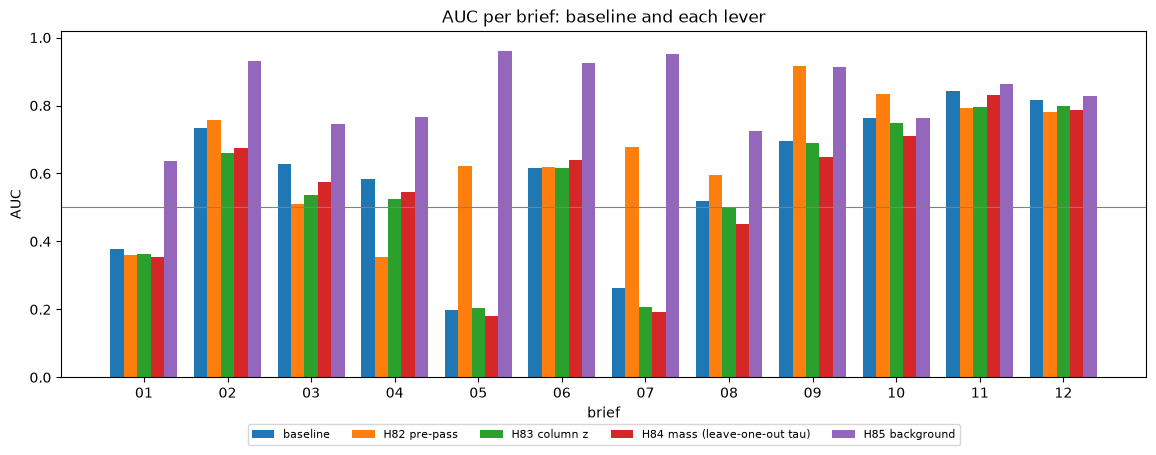

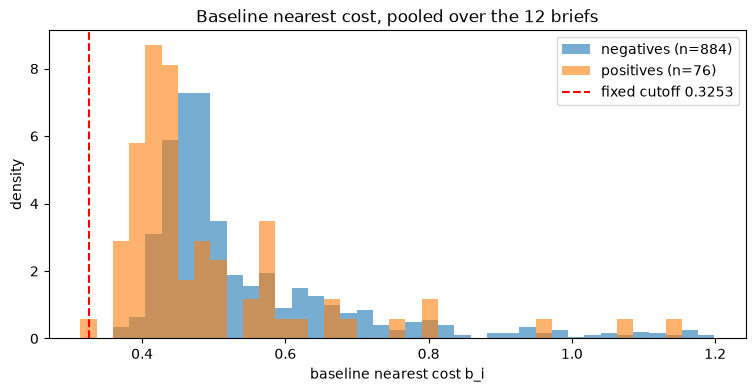

pooled nearest cost: positives median 0.4350 (min 0.3138), negatives median 0.4865 (min 0.3658)

In [13]:
fig, ax = plt.subplots(figsize=(14, 4.5))
series = [("baseline", "baseline"), ("H82", "H82 pre-pass"), ("H83", "H83 column z"), ("H84_lobo", "H84 mass (leave-one-out tau)"), ("H85", "H85 background")]
width = 0.8 / len(series)
for k, (name, label) in enumerate(series):
    ax.bar(np.arange(12) + k * width, [AUC[name][b] for b in BRIEF_IDS], width, label=label)
ax.set_xticks(np.arange(12) + 0.4 - width / 2, [b[-2:] for b in BRIEF_IDS])
ax.set_xlabel("brief"); ax.set_ylabel("AUC"); ax.set_ylim(0.0, 1.02); ax.axhline(0.5, color="grey", lw=0.8)
ax.set_title("AUC per brief: baseline and each lever"); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
plt.show()

pos_costs = np.concatenate([BASE_COST[b][LAB[b]["pos"]] for b in BRIEF_IDS])
neg_costs = np.concatenate([BASE_COST[b][LAB[b]["neg"]] for b in BRIEF_IDS])
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(min(pos_costs.min(), neg_costs.min()), max(pos_costs.max(), neg_costs.max()), 40)
ax.hist(neg_costs, bins=bins, alpha=0.6, density=True, label=f"negatives (n={len(neg_costs)})")
ax.hist(pos_costs, bins=bins, alpha=0.6, density=True, label=f"positives (n={len(pos_costs)})")
ax.axvline(DIFF_CHANGED_COST, color="red", ls="--", label=f"fixed cutoff {DIFF_CHANGED_COST:.4f}")
ax.set_xlabel("baseline nearest cost b_i"); ax.set_ylabel("density"); ax.set_title("Baseline nearest cost, pooled over the 12 briefs")
ax.legend(); plt.show()
console.print(f"pooled nearest cost: positives median {np.median(pos_costs):.4f} (min {pos_costs.min():.4f}), negatives median {np.median(neg_costs):.4f} (min {neg_costs.min():.4f})")

## E17-H86 - per-pair Otsu cutoff

For a pair, Otsu's split is exact on the sample: the baseline values `b_i` of all report statements (neutral ones
included) are sorted, and over the midpoints between neighbouring distinct values the threshold with the largest
between-class variance `w0 * w1 * (mu0 - mu1)^2` is chosen (an exact tie goes to the lower threshold). A statement is a
match iff `b_i <= threshold`. Balanced accuracy is read on the non-neutral statements: the mean of the recall on the
positives (marked match) and the recall on the negatives (marked no match). The fixed-cutoff map uses
`DIFF_CHANGED_COST`.

In [14]:
def otsu_threshold(values):
    "Exact Otsu split of a sample: the midpoint between neighbouring distinct sorted values with the largest between-class variance"
    v = np.sort(values)
    distinct = np.unique(v)
    best_var, best_t = -1.0, None
    for t in (distinct[:-1] + distinct[1:]) / 2:
        lo, hi = v[v <= t], v[v > t]
        var = (len(lo) / len(v)) * (len(hi) / len(v)) * (lo.mean() - hi.mean()) ** 2
        if var > best_var:                       # strict: an exact tie keeps the lower threshold
            best_var, best_t = var, float(t)
    return best_t


def balanced_accuracy(match, pos, neg):
    "Mean of the recall on positives (match) and the recall on negatives (no match)"
    return float((match[pos].mean() + (~match[neg]).mean()) / 2)


H86 = {}
for bid in BRIEF_IDS:
    b = BASE_COST[bid]
    t = otsu_threshold(b)
    lab = LAB[bid]
    fixed_match, otsu_match = b <= DIFF_CHANGED_COST, b <= t
    H86[bid] = {"fixed_ba": balanced_accuracy(fixed_match, lab["pos"], lab["neg"]), "otsu_ba": balanced_accuracy(otsu_match, lab["pos"], lab["neg"]),
                "otsu_threshold": t, "n_match_fixed": int(fixed_match.sum()), "n_match_otsu": int(otsu_match.sum()),
                "otsu_tpr": float(otsu_match[lab["pos"]].mean()), "otsu_tnr": float((~otsu_match[lab["neg"]]).mean()),
                "fixed_tpr": float(fixed_match[lab["pos"]].mean()), "fixed_tnr": float((~fixed_match[lab["neg"]]).mean())}

fixed_mean = float(np.mean([H86[b]["fixed_ba"] for b in BRIEF_IDS]))
otsu_mean = float(np.mean([H86[b]["otsu_ba"] for b in BRIEF_IDS]))
h86_killed = fixed_mean >= H86_GATE_BA
h86_clauses = {"otsu_mean_ba_ge_0.70": {"value": otsu_mean, "ok": bool(otsu_mean >= H86_BAR_BA)},
               "otsu_minus_fixed_ge_0.10": {"value": otsu_mean - fixed_mean, "ok": bool(otsu_mean - fixed_mean >= H86_BAR_GAIN)}}
h86_clauses["bar_met"] = bool(all(c["ok"] for c in h86_clauses.values()))
DECISION["E17-H86"] = {"gate": {"fixed_mean_ba": fixed_mean, "threshold": H86_GATE_BA, "killed": bool(h86_killed)}, "clauses": h86_clauses,
                       "otsu_mean_ba": otsu_mean,
                       "verdict_by_bar": "Killed-at-gate" if h86_killed else ("Confirmed" if h86_clauses["bar_met"] else "Refuted")}

table = Table(title="E17-H86 per brief - balanced accuracy of the fixed cutoff and of the Otsu split")
for col in ("brief", "fixed BA", "fixed match", "fixed TPR/TNR", "Otsu BA", "Otsu threshold", "Otsu match", "Otsu TPR/TNR", "Otsu - fixed"):
    table.add_column(col, justify="left" if col == "brief" else "right")
for bid in BRIEF_IDS:
    h = H86[bid]
    table.add_row(bid, f"{h['fixed_ba']:.4f}", str(h["n_match_fixed"]), f"{h['fixed_tpr']:.2f}/{h['fixed_tnr']:.2f}", f"{h['otsu_ba']:.4f}",
                  f"{h['otsu_threshold']:.4f}", str(h["n_match_otsu"]), f"{h['otsu_tpr']:.2f}/{h['otsu_tnr']:.2f}", cell(h["otsu_ba"] - h["fixed_ba"]))
table.add_row("mean", f"{fixed_mean:.4f}", "", "", f"{otsu_mean:.4f}", "", "", "", f"{otsu_mean - fixed_mean:+.4f}")
console.print(table)
console.print(f"H86 gate: fixed-cutoff mean BA {fixed_mean:.4f} vs {H86_GATE_BA} -> {'KILLED at the gate' if h86_killed else 'passed'}")
console.print(f"H86 bar: Otsu mean BA {otsu_mean:.4f} >= {H86_BAR_BA} -> {h86_clauses['otsu_mean_ba_ge_0.70']['ok']}; "
              f"difference {otsu_mean - fixed_mean:+.4f} >= {H86_BAR_GAIN} -> {h86_clauses['otsu_minus_fixed_ge_0.10']['ok']}; verdict_by_bar {DECISION['E17-H86']['verdict_by_bar']}")

# Otsu split on the score of every lever that is confirmed (reported, no bar)
CONFIRMED = {"H82": "E17-H82", "H83": "E17-H83", "H85": "E17-H85"}
confirmed_scores = [n for n, h in CONFIRMED.items() if DECISION[h]["verdict_by_bar"] == "Confirmed"]
confirmed_scores += [f"H84_tau{t:.2f}" for t in TAUS if DECISION["E17-H84"]["verdict_by_bar"] == "Confirmed" and per_tau[f"{t:.2f}"]["bar_met"]]
LEVER_OTSU = {}
for name in confirmed_scores:
    LEVER_OTSU[name] = {}
    for bid in BRIEF_IDS:
        cost_like = -S[name][bid]
        t = otsu_threshold(cost_like)
        LEVER_OTSU[name][bid] = {"threshold": t, "ba": balanced_accuracy(cost_like <= t, LAB[bid]["pos"], LAB[bid]["neg"]), "n_match": int((cost_like <= t).sum())}
    console.print(f"Otsu split on {name}: mean BA {np.mean([v['ba'] for v in LEVER_OTSU[name].values()]):.4f} (reported, no bar)")
if not confirmed_scores:
    console.print("no lever of H82 to H85 is confirmed: no Otsu split on a lever score is read")

                      E17-H86 per brief - balanced accuracy of the fixed cutoff and of the Otsu split                      
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ brief    ┃ fixed BA ┃ fixed match ┃ fixed TPR/TNR ┃ Otsu BA ┃ Otsu threshold ┃ Otsu match ┃ Otsu TPR/TNR ┃ Otsu - fixed ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ brief-01 │   0.5000 │           0 │     0.00/1.00 │  0.5519 │         0.7318 │         83 │    1.00/0.10 │      +0.0519 │
│ brief-02 │   0.5000 │           0 │     0.00/1.00 │  0.4211 │         0.7284 │         83 │    0.75/0.09 │      -0.0789 │
│ brief-03 │   0.5000 │           0 │     0.00/1.00 │  0.3983 │         0.6799 │         80 │    0.67/0.13 │      -0.1017 │
│ brief-04 │   0.5000 │           0 │     0.00/1.00 │  0.5519 │         0.6945 │         83 │    1.00/0.10 │      +0.0519 │
│ brief-05 │   0.5000 │           0 │     0.00/1.00 │  0.5641 │         0.6946 │         81 │    1.00/0.13 │      +0.0641 │
│ brief-06 │   0.5000 │           0 │     0.00/1.00 │  0.5563 │         0.7101 │         83 │    1.00/0.11 │      +0.0563 │
│ brief-07 │   0.5000 │           0 │     0.00/1.00 │  0.4145 │         0.7448 │         84 │    0.75/0.08 │      -0.0855 │
│ brief-08 │   0.5000 │           0 │     0.00/1.00 │  0.5608 │         0.6972 │         82 │    1.00/0.12 │      +0.0608 │
│ brief-09 │   0.5714 │           1 │     0.14/1.00 │  0.5039 │         0.6757 │         79 │    0.86/0.15 │      -0.0675 │
│ brief-10 │   0.5000 │           0 │     0.00/1.00 │  0.5139 │         0.6526 │         79 │    0.88/0.15 │      +0.0139 │
│ brief-11 │   0.5000 │           0 │     0.00/1.00 │  0.5513 │         0.6698 │         79 │    0.93/0.17 │      +0.0513 │
│ brief-12 │   0.5000 │           0 │     0.00/1.00 │  0.5466 │         0.6433 │         78 │    0.92/0.18 │      +0.0466 │
│ mean     │   0.5060 │             │               │  0.5112 │                │            │              │      +0.0053 │
└──────────┴──────────┴─────────────┴───────────────┴─────────┴────────────────┴────────────┴──────────────┴──────────────┘

H86 gate: fixed-cutoff mean BA 0.5060 vs 0.65 -> passed

H86 bar: Otsu mean BA 0.5112 >= 0.7 -> False; difference +0.0053 >= 0.1 -> False; verdict_by_bar Refuted

Otsu split on H85: mean BA 0.7366 (reported, no bar)

## Section reading

For every score the leaf sections (neutral ones left out, part-heading-only sections included) are ranked by the mean
relevance of their statements. The table lists, for the baseline, the ranked sections of a few briefs and for every
score the share of the target sections in the top 2, averaged over the 12 briefs.

In [15]:
table = Table(title="Baseline section ranking per brief (top 3 of the ranked leaf sections) and share of targets in the top 2")
for col in ("brief", "targets", "top 3 sections by mean relevance", "share in top 2"):
    table.add_column(col)
for bid in BRIEF_IDS:
    ranked, share = SECTION["baseline"][bid]
    table.add_row(bid, "; ".join(LAB[bid]["targets"]), "; ".join(ranked[:3]), f"{share:.2f}")
console.print(table)

table = Table(title="Share of target sections in the top 2, per brief")
table.add_column("brief")
for name in SCORES:
    table.add_column(name, justify="right")
for bid in BRIEF_IDS:
    table.add_row(bid, *[f"{SECTION[name][bid][1]:.2f}" for name in SCORES])
table.add_row("mean", *[f"{SUMMARY[name]['top2_share']:.4f}" for name in SCORES])
console.print(table)

                                                Baseline section ranking per brief (top 3 of the ranked leaf sections) and share of targets in the top 2                                                
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ brief    ┃ targets                                                                            ┃ top 3 sections by mean relevance                                                    ┃ share in top 2 ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ brief-01 │ Barriers keeping the next wave from benefiting                                     │ AI in Society; Bias and data; Most companies have accelerated rollout in the past   │ 0.00           │
│          │                                                                                    │ 24 months                                                                           │                │
│ brief-02 │ Workforce impact                                                                   │ AI in Society; Most companies have accelerated rollout in the past 24 months;       │ 0.00           │
│          │                                                                                    │ Easier tools and cost reduction are driving adoption                                │                │
│ brief-03 │ Trustworthy and governed AI                                                        │ Bias and data; AI in Society; Future                                                │ 0.00           │
│ brief-04 │ Easier tools and cost reduction are driving adoption                               │ AI in Society; Most companies have accelerated rollout in the past 24 months;       │ 0.00           │
│          │                                                                                    │ Easier tools and cost reduction are driving adoption                                │                │
│ brief-05 │ AI use cases cut across business operations                                        │ Easier tools and cost reduction are driving adoption; AI in Society; Most companies │ 0.00           │
│          │                                                                                    │ have accelerated rollout in the past 24 months                                      │                │
│ brief-06 │ Adoption has remained steady at large organizations; Most companies have           │ AI in Society; Most companies have accelerated rollout in the past 24 months;       │ 0.50           │
│          │ accelerated rollout in the past 24 months                                          │ Adoption has remained steady at large organizations                                 │                │
│ brief-07 │ Methodology                                                                        │ Bias and data; AI in Society; Future                                                │ 0.00           │
│ brief-08 │ Barriers keeping the next wave from benefiting; Trustworthy and governed AI        │ AI in Society; Bias and data; Trustworthy and governed AI                           │ 0.00           │
│ brief-09 │ Teaching the topic                                                                 │ Teaching the topic; Future; AI in Society                                           │ 1.00           │
│ brief-10 │ Bias and data                                                                      │ Bias and data; AI in Society; Future                                                │ 1.00           │
│ brief-11 │ Future                                                                             │ Future; AI in Society; Bias and data                                               

                           Share of target sections in the top 2, per brief                            
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┓
┃ brief    ┃ baseline ┃    H82 ┃    H83 ┃ H84_tau0.02 ┃ H84_tau0.05 ┃ H84_tau0.10 ┃ H84_lobo ┃    H85 ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━┩
│ brief-01 │     0.00 │   0.00 │   0.00 │        0.00 │        0.00 │        0.00 │     0.00 │   0.00 │
│ brief-02 │     0.00 │   1.00 │   0.00 │        1.00 │        1.00 │        1.00 │     1.00 │   1.00 │
│ brief-03 │     0.00 │   0.00 │   0.00 │        0.00 │        0.00 │        0.00 │     0.00 │   1.00 │
│ brief-04 │     0.00 │   0.00 │   0.00 │        0.00 │        0.00 │        0.00 │     0.00 │   0.00 │
│ brief-05 │     0.00 │   1.00 │   0.00 │        0.00 │        0.00 │        0.00 │     0.00 │   1.00 │
│ brief-06 │     0.50 │   1.00 │   1.00 │        0.50 │        0.50 │        0.50 │     0.50 │   1.00 │
│ brief-07 │     0.00 │   1.00 │   0.00 │        0.00 │        0.00 │        0.00 │     0.00 │   1.00 │
│ brief-08 │     0.00 │   0.50 │   0.00 │        0.50 │        0.00 │        0.00 │     0.00 │   0.50 │
│ brief-09 │     1.00 │   1.00 │   1.00 │        1.00 │        1.00 │        1.00 │     1.00 │   1.00 │
│ brief-10 │     1.00 │   1.00 │   0.00 │        1.00 │        1.00 │        1.00 │     1.00 │   0.00 │
│ brief-11 │     1.00 │   1.00 │   0.00 │        1.00 │        1.00 │        1.00 │     1.00 │   1.00 │
│ brief-12 │     1.00 │   1.00 │   1.00 │        1.00 │        1.00 │        1.00 │     1.00 │   1.00 │
│ mean     │   0.3750 │ 0.7083 │ 0.2500 │      0.5000 │      0.4583 │      0.4583 │   0.4583 │ 0.7083 │
└──────────┴──────────┴────────┴────────┴─────────────┴─────────────┴─────────────┴──────────┴────────┘

## Metrics JSON

Every measured number, the decision values and the verdict by bar of each hypothesis are written to
`reports/E17-relevance-map-metrics.json`.

In [16]:
def per_query(qids):
    return {q: {name: AUC[name][q] for name in SCORES if q in AUC[name]} for q in qids}


metrics = {
    "batch": "E17",
    "written_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "environment": {"docdistance": docdistance.__version__, "python": platform.python_version(), "numpy": np.__version__,
                    "POT": ot.__version__, "encoder_backend": dd.backend, "reader": "default (auto by extension)",
                    "DIFF_CHANGED_COST": DIFF_CHANGED_COST, "ANISOTROPY_MIN_POOL": ANISOTROPY_MIN_POOL},
    "fixture_sha256": fixture_sha, "fixture_sha256_equals_registration": fixture_sha == REG["fixture_sha256"],
    "statement_counts": {"report": N_REPORT, "briefs": {b: len(BRIEF_TEXTS[b]) for b in BRIEF_IDS}, "controls": {c: len(CONTROL_TEXTS[c]) for c in CONTROL_IDS}},
    "section_statement_counts": {path: n for path, n in counts.items()},
    "label_counts": {q: {"positives": int(l["pos"].sum()), "negatives": int(l["neg"].sum()), "hard_negatives": None if l["hard"] is None else int(l["hard"].sum())} for q, l in LAB.items()},
    "neutral_statements": int(IS_NEUTRAL.sum()),
    "pooled_statement_counts": POOL_N,
    "auc_per_brief": per_query(BRIEF_IDS), "auc_hard_negatives_per_brief": AUC_HARD, "auc_per_control": per_query(CONTROL_IDS),
    "lobo_tau_per_brief": LOBO_TAU,
    "summary_per_score": SUMMARY,
    "section_reading": {name: {b: {"ranked_sections": SECTION[name][b][0], "top2_share": SECTION[name][b][1]} for b in BRIEF_IDS} for name in SCORES},
    "baseline_cost_quantiles": QUANT, "baseline_lowest_statement_per_brief": TOP1,
    "h86_per_brief": H86, "h86_otsu_on_confirmed_levers": LEVER_OTSU,
    "decisions": DECISION,
    "verdict_by_bar": {"E17-H82": DECISION["E17-H82"]["verdict_by_bar"], "E17-H83": DECISION["E17-H83"]["verdict_by_bar"],
                       "E17-H84": DECISION["E17-H84"]["verdict_by_bar"], "E17-H85": DECISION["E17-H85"]["verdict_by_bar"],
                       "E17-H86": DECISION["E17-H86"]["verdict_by_bar"]},
    "wall_seconds": round(time.time() - T_START, 1),
}
METRICS_FILE.write_text(json.dumps(metrics, indent=1, default=float), encoding="utf-8")
console.print(f"written {METRICS_FILE.relative_to(ROOT)} ({METRICS_FILE.stat().st_size} bytes)")
console.print({k: v for k, v in metrics["verdict_by_bar"].items()})

written reports/E17-relevance-map-metrics.json (103666 bytes)

{'E17-H82': 'Refuted', 'E17-H83': 'Refuted', 'E17-H84': 'Refuted', 'E17-H85': 'Confirmed', 'E17-H86': 'Refuted'}

## Conclusions

Verdicts are read on the registered bars only. The batch gate passed: the baseline mean AUC is 0.5865, far below 0.95,
so the baseline does not rank the report on this fixture (three briefs, 01, 05 and 07, read below 0.5, at 0.3766, 0.1987
and 0.2632). Pooled sizes are 99 to 106 statements, above `ANISOTROPY_MIN_POOL` = 71, so the own gate of `E17-H82` passed.

| hypothesis | mean AUC diff | briefs > 0 of 12 | control mean AUC diff | verdict by bar |
|---|---|---|---|---|
| E17-H82 pre-pass | +0.0653 | 7 | +0.2903 | Refuted |
| E17-H83 column standardisation | -0.0325 | 2 | +0.0186 | Refuted |
| E17-H84 mass, tau 0.02 / 0.05 / 0.10 | -0.0410 / -0.0342 / -0.0347 | 1 / 1 / 1 | -0.0085 / -0.0130 / -0.0170 | Refuted |
| E17-H84 leave-one-brief-out | -0.0371 | 1 | not read | (part of the H84 verdict) |
| E17-H85 background contrast | +0.2474 | 11 | +0.1675 | Confirmed |
| E17-H86 Otsu split (balanced accuracy) | +0.0053 (0.5112 against 0.5060) | not applicable | not applicable | Refuted |

- **E17-H82 (pre-pass)** - the mean gain (+0.0653) and the control clause (+0.2903) meet the bar, but the difference is above 0 in 7 briefs, not 10. Refuted on the count clause. The gain is carried by briefs 05 (+0.4231), 07 (+0.4145) and 09 (+0.2211); briefs 08 (+0.0743), 10 (+0.0729), 02 (+0.0230) and 06 (+0.0047) gain little; five briefs lose (04 -0.2294, 03 -0.1169, 11 -0.0523, 12 -0.0343, 01 -0.0173). The bootstrap interval of the mean difference, [-0.0353, +0.1754], contains 0. The control mean AUC rises from 0.6780 to 0.9683, so the pre-pass separates part 1 from part 2 of the report for a summary of part 1 much better, but it does not rank the target sections of an independent brief reliably. The AUC against the hard negatives rises from 0.6282 to 0.6668 (reported)
- **E17-H83 (column standardisation)** - mean difference -0.0325, positive in 2 briefs. Refuted. The score is below the baseline in 10 briefs
- **E17-H84 (assignment mass)** - all three temperatures do not beat the baseline in 11 of 12 briefs (mean differences -0.0410, -0.0342, -0.0347) and the leave-one-brief-out reading loses too (-0.0371, 1 brief above 0). Refuted. The top-2 section share rises from 0.3750 to 0.5000, 0.4583 and 0.4583, which is the registered prediction on sections, but the statement ranking gets worse
- **E17-H85 (background contrast)** - mean difference +0.2474 (bootstrap interval [+0.1277, +0.3854]), positive in 11 of 12 briefs (brief 10 is exactly unchanged at 0.7622), control mean AUC +0.1675. All three clauses are met: Confirmed on this fixture. The mean AUC is 0.8340 and the top-2 section share 0.7083. The registered prediction of a gain of 0.05 or more is met many times over. The largest gains are on the briefs whose baseline reads below 0.5: brief 05 +0.7628, brief 07 +0.6875, brief 01 +0.2597. The mechanism of the baseline failure is visible in the lowest-cost table: for 5 of the 12 briefs the lowest-cost statement is in `Overview` or `Key findings`, and `AI in Society` is the top-ranked section of 6 briefs. These statements are near every brief, and the subtraction removes exactly that
- **E17-H86 (relative cut)** - the gate passed: the fixed cutoff 0.3253 marks 1 statement of 93 as a match over all 12 briefs (brief 09), balanced accuracy 0.5060. The Otsu split reaches 0.5112, 0.0053 above the fixed cutoff and below 0.70. Refuted. The Otsu split of the baseline marks 78 to 84 of 93 statements as a match (true positive rate 0.67 to 1.00, true negative rate 0.08 to 0.18): the baseline values form no two groups for the split to find. Read on the score of the confirmed lever `H85` (reported, no bar), the Otsu split reaches a mean balanced accuracy of 0.7366

**What the fixture cannot show** - the report is two articles on one broad topic, and the 12 briefs are written by one author with a fixed shape (four situation sentences and two uncovered client facts) and the report in view. The labels are at section level, so a statement outside the target sections that bears on the brief is counted as a negative (the barriers and workforce sections both speak of skills). With 12 briefs the sign test has little power, and the bootstrap interval of `H82` contains 0. The lever `H85` uses the other 11 briefs as background: the briefs share one genre (a client situation), so the background measures nearness to that genre, and the background contains briefs that share a target section with the scored brief (01 and 08, 03 and 08); both facts are not separable here. In use `H85` needs several briefs for one report. The control reading rests on one article and 7 summaries of it. A confirmed lever on this fixture is a result for this fixture; whether it ships is a separate decision.